In [5]:
!pip install gym_bandits
import gym
import gym_bandits
import matplotlib.pyplot as plt
import numpy as np
np.bool8=np.bool_

'env=gym.make(\'MultiarmedBandits-v0\')\nprint(env.observation_space)\nprint(env.action_space)\nn_arms=env.action_space.n\nnum_episodes=500\nepsilon=0.1\nq_values=np.zeros(n_arms)\ncounts=np.zeros(n_arms)\nreward_sums=np.zeros(n_arms)\nall_rewards=[]\naction_history=[]\nwarnings.filterwarnings(\'ignore\',category=DeprecationWarning)\nfor episode in range(num_episodes):\n  env.reset()\n  if np.random.rand()<epsilon:\n    action=env.action_space.sample()\n  else:\n    action=np.argmax(q_values)\n  observation,reward,done,info=env.step(action)\n  counts[action]+=1\n  reward_sums[action]+=reward\n  q_values[action]=reward_sums[action]/counts[action]\n  all_rewards.append(reward)\n  action_history.append(action)\nenv.close()\nprint("Estimated Q-values for each arm:", np.round(q_values, 2))\nprint("Number of times each arm was Selected:", counts.astype(int))\nprint("Average reward over all episodes:",round(np.mean(all_rewards),3))'

In [6]:
env=gym.make('MultiarmedBandits-v0')
print(env.observation_space)
print(env.action_space)
n_arms=env.action_space.n
num_episodes=500
epsilon=0.1
q_values=np.zeros(n_arms)
counts=np.zeros(n_arms)
reward_sums=np.zeros(n_arms)
all_rewards=[]
action_history=[]

Discrete(1)
Discrete(10)


In [8]:
import warnings
warnings.filterwarnings('ignore',category=DeprecationWarning)
for episode in range(num_episodes):
  env.reset()
  if np.random.rand()<epsilon:
    action=env.action_space.sample()
  else:
    action=np.argmax(q_values)
  observation,reward,done,info=env.step(action)
  counts[action]+=1
  reward_sums[action]+=reward
  q_values[action]=reward_sums[action]/counts[action]
  all_rewards.append(reward)
  action_history.append(action)
env.close()
print("Estimated Q-values for each arm:", np.round(q_values, 2))
print("Number of times each arm was Selected:", counts.astype(int))
print("Average reward over all episodes:",round(np.mean(all_rewards),3))

Estimated Q-values for each arm: [ 0.01 -0.26 -0.27 -0.89 -0.29 -0.14 -0.38 -0.06 -0.26 -0.22]
Number of times each arm was Selected: [399  10   3   7  10  13  12  29  10   7]
Average reward over all episodes: -0.038


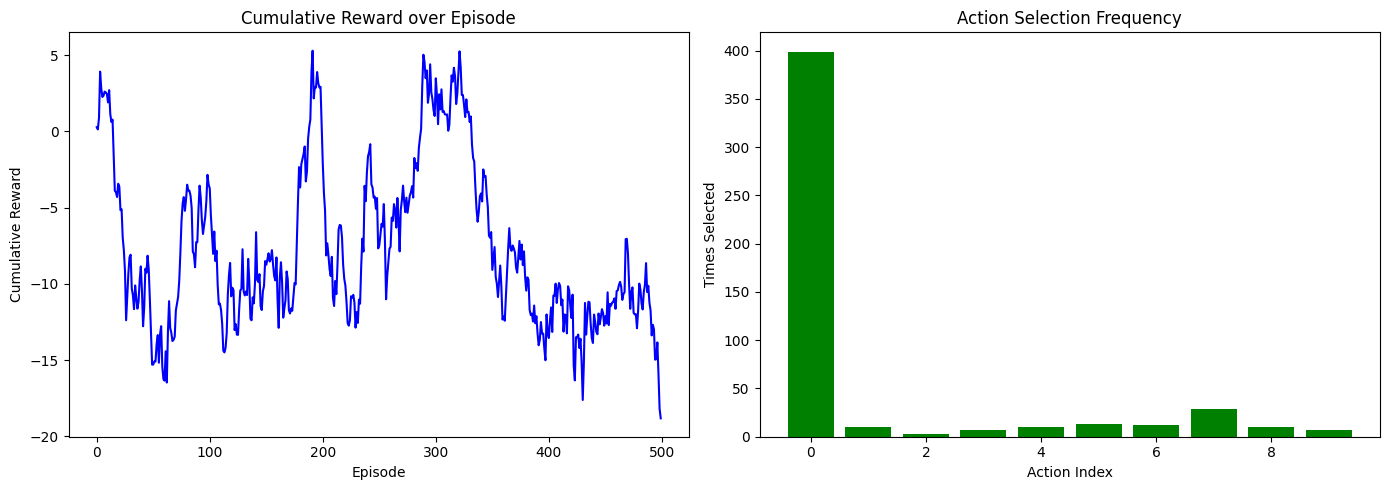

In [9]:

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(all_rewards), color='blue')
plt.title('Cumulative Reward over Episode')
plt.xlabel('Episode')
plt.ylabel('Cumulative Reward')

plt.subplot(1, 2, 2)
plt.bar(np.arange(n_arms), counts, color='green')
plt.title('Action Selection Frequency')
plt.xlabel('Action Index')
plt.ylabel('Times Selected')
plt.tight_layout()
plt.show()